# PerfuSense AI · Lesson 3: what our small mat really sees

Lessons 1 and 2 cheated a little. They showed the model the **whole bed**. Our real mat is 30×30 cm under the lower back. It never sees the head, the shoulders or the legs.

This lesson cuts each hospital map down to what our mat would see, and measures the honest cost:

1. Find the real distance between sensors, **from the data**.
2. Decide where the mat lies under each person.
3. Train on the patch and compare with the whole bed.
4. Test what happens when the mat is placed badly.
5. Check whether the small mat can look empty while someone is in the bed.

> Research prototype, not a medical device. Nothing here is a clinical claim.

In [1]:
import sys
import inspect
import json
import time

sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import keras
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from perfusense_ai import data as D
from perfusense_ai import model as M


def show(*functions):
    """Print the real source code of our shared functions."""
    for f in functions:
        print(inspect.getsource(f))

t0 = time.time()
recordings = D.load_pmd() + [r for r in D.load_popu() if r["label"] != "prone"]
print(f"{len(recordings)} recordings loaded in {time.time() - t0:.0f} s")

1481 recordings loaded in 29 s


## Step 1 · How far apart are the sensors?

To cut 30 cm we must know how many sensors make 30 cm. I searched for the datasheets of both mats and for the papers. **I could not find an official number**, so we measure it.

We know each person's height. On a flat supine map we can count how many rows the body covers from head to heel. Then:

**cm per sensor ≈ height ÷ rows covered**

         median   std  count
dataset                     
pmd        2.85  0.13     13
popu       2.85  0.11     60


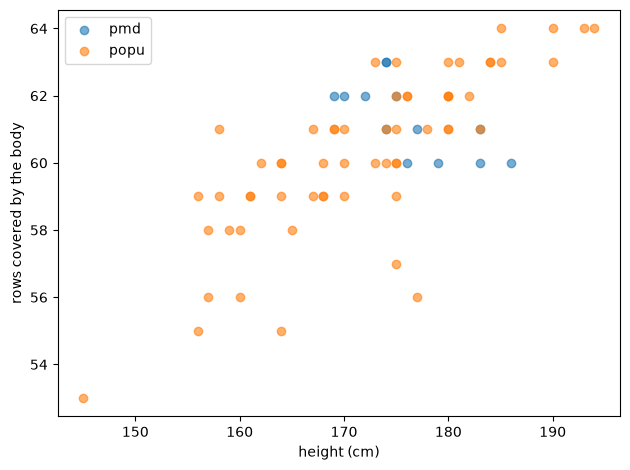

In [2]:
def body_rows(mean_map):
    """How many rows have pressure, from the head to the heels."""
    rows = np.flatnonzero(mean_map.max(axis=1) > 0.05 * mean_map.max())
    return rows.max() - rows.min() + 1

info = pd.read_csv(D.pmd_exp1_dir() / "subject-info-i.csv", encoding="utf-16")
heights = {f"pmd-{int(r.iloc[0])}": float(r.iloc[2]) for _, r in info.iterrows() if r.iloc[0] > 0}
for p in range(1, 61):
    with open(D.popu_dir() / str(p) / "supine1_0.json") as f:
        heights[f"popu-{p}"] = float(json.load(f)["height"])

rows = []
for r in recordings:
    flat_supine = r["position"] in ("1", "supine1")
    if flat_supine:
        rows.append({"dataset": r["dataset"], "height_cm": heights[r["person"]],
                     "rows": body_rows(r["frames"].mean(axis=0))})
table = pd.DataFrame(rows)
table["cm_per_sensor"] = table.height_cm / table.rows
print(table.groupby("dataset").cm_per_sensor.agg(["median", "std", "count"]).round(2))

for name, part in table.groupby("dataset"):
    plt.scatter(part.height_cm, part.rows, label=name, alpha=0.6)
plt.xlabel("height (cm)"); plt.ylabel("rows covered by the body"); plt.legend(); plt.tight_layout(); plt.show()

Both mats come out at about **2.85 cm per sensor** with little spread, and our mat has 3.0 cm per cell (30 cm ÷ 10). That is a lucky and very useful result:

> **A 10×10 block of hospital sensors is almost exactly our mat.** No resizing, no averaging. We just cut it out.

Honest notes: this is an estimate. A lying body is a bit shorter than its standing height, and feet may not press. The spacing **across** the mat (columns) cannot be measured this way, so we assume it is the same as along the mat.

## Step 2 · Where does the mat lie?

The guide says the mat goes under the lower back. A first idea: put the 10×10 box where the pressure is highest on a flat supine map, because the hips carry the most weight.

Let's test that simple idea before trusting it.

In [3]:
def naive_box(mean_map):
    """First idea: the 10 x 10 box with the most pressure anywhere on the body."""
    c = np.pad(np.cumsum(np.cumsum(mean_map, axis=0), axis=1), ((1, 0), (1, 0)))
    box = c[10:, 10:] - c[:-10, 10:] - c[10:, :-10] + c[:-10, :-10]
    return np.unravel_index(np.argmax(box), box.shape)

maps = {}
for r in recordings:
    flat = r["position"] in ("1", "8", "9", "10", "11", "12") if r["dataset"] == "pmd" else r["label"] == "supine"
    if flat:
        maps.setdefault(r["person"], []).append(D.pad_to_width(r["frames"]).mean(axis=0))
maps = {person: np.mean(m, axis=0) for person, m in maps.items()}

top_rows = pd.Series({p: naive_box(m)[0] for p, m in maps.items()})
print("top row of the box:", top_rows.describe()[["min", "50%", "max"]].to_dict())
print("people where the box lands above row 18 (the chest or shoulders):", int((top_rows < 18).sum()), "of", len(top_rows))

top row of the box: {'min': 11.0, '50%': 25.0, 'max': 31.0}
people where the box lands above row 18 (the chest or shoulders): 13 of 73


For some people the highest pressure is at the **shoulders**, not the hips, so the box lands in the wrong place. Rule improved: the centre of the box must lie **42–62 % of the way from head to heel**, the part of the body where the hips are, for every body size. (A wider search, the middle third, still caught the chest of some people. The plot below is how I found out.)

In [4]:
show(D.sacrum_point, D.crop_patch, D.mat_positions, D.patch_view)

def sacrum_point(mean_map):
    """Top-left corner of the mat on a flat supine map: the 10 x 10 box with the most pressure, with
    its centre 42-62 % of the way from head to heel. Searching more widely can pick the shoulders."""
    rows = np.flatnonzero(mean_map.max(axis=1) > 0.05 * mean_map.max())
    head, feet = rows.min(), rows.max()
    c = np.pad(np.cumsum(np.cumsum(mean_map, axis=0), axis=1), ((1, 0), (1, 0)))
    box = c[GRID:, GRID:] - c[:-GRID, GRID:] - c[GRID:, :-GRID] + c[:-GRID, :-GRID]
    centre = np.arange(box.shape[0]) + GRID / 2
    box[(centre < head + 0.42 * (feet - head)) | (centre > head + 0.62 * (feet - head))] = -1
    r0, c0 = np.unravel_index(np.argmax(box), box.shape)
    return int(r0), int(c0)

def crop_patch(frames, top, left, size=GRID):
    """Cut a size x size sensor patch. Sensors are about 2.9 cm apart, so 10 sensors is about 29 cm."""
    h, w = frames.shape[1:]
    top = int(np.clip(top, 0, h - size))
    left = int(np.clip(left, 0, w - size))
  

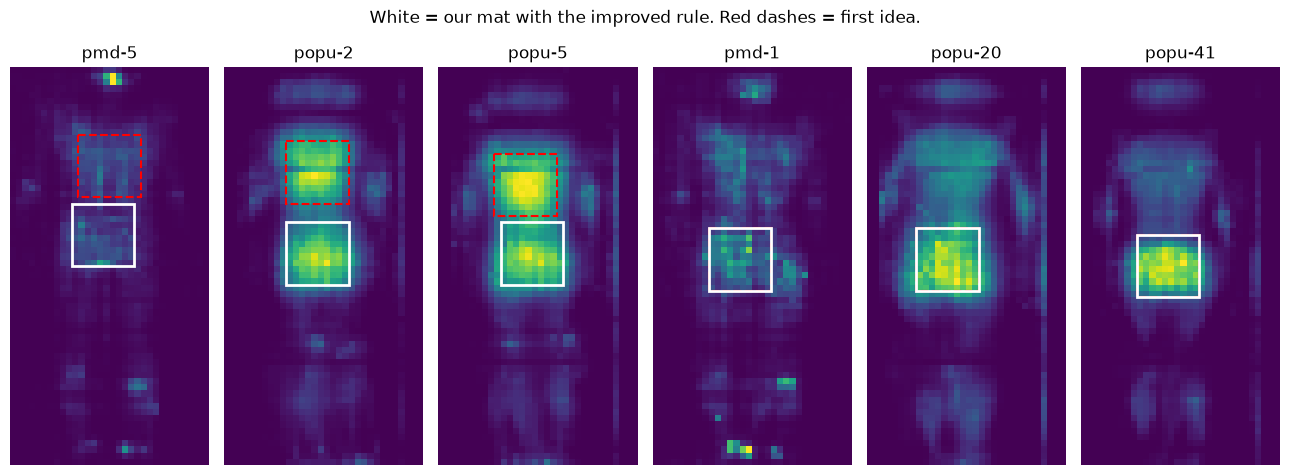

In [5]:
positions = D.mat_positions(recordings)

examples = ["pmd-5", "popu-2", "popu-5", "pmd-1", "popu-20", "popu-41"]
fig, axes = plt.subplots(1, 6, figsize=(13, 5))
for ax, person in zip(axes, examples):
    ax.imshow(maps[person])
    naive = naive_box(maps[person])
    ax.add_patch(patches.Rectangle((naive[1] - .5, naive[0] - .5), 10, 10, fill=False, ec="red", ls="--", lw=1.5))
    top, left = positions[person]
    ax.add_patch(patches.Rectangle((left - .5, top - .5), 10, 10, fill=False, ec="white", lw=2))
    ax.set_title(person); ax.axis("off")
plt.suptitle("White = our mat with the improved rule. Red dashes = first idea."); plt.tight_layout(); plt.show()

### Decision: the mat stays still while the person turns

This matters. There are two ways to cut the patch:

| Option | Meaning | Realistic? |
|---|---|---|
| Follow the pressure in every recording | the patch moves with the body | No. A real mat does not move |
| **One fixed place per person** | set once from flat supine, used for all their postures | Yes. The mat is placed once, then the patient turns on it |

We use the fixed place. When someone rolls left, their hips slide across the mat, and that slide is real information.

Now look at what the mat sees:

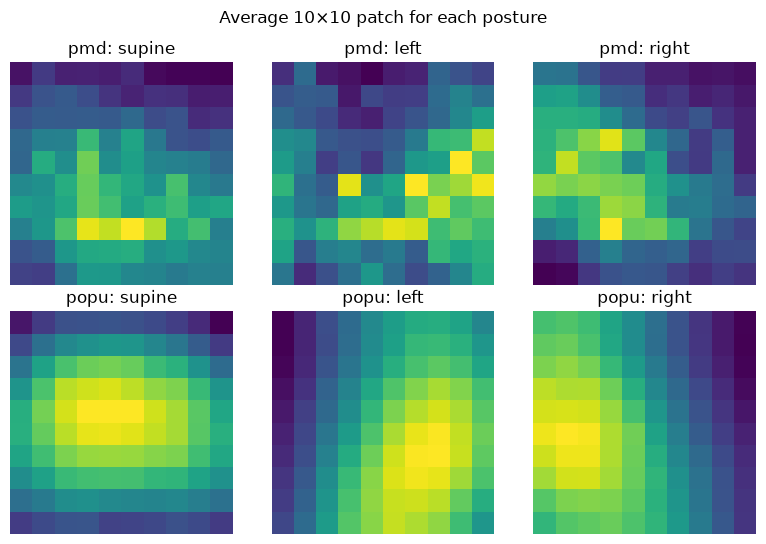

share of the body's total pressure that lands on our mat:
dataset   pmd  popu
label              
left     0.16  0.24
right    0.18  0.23
supine   0.24  0.30


In [6]:
view = D.patch_view(positions)

fig, axes = plt.subplots(2, 3, figsize=(8, 5.5))
for row, name in enumerate(["pmd", "popu"]):
    for col, label in enumerate(D.CLASSES):
        patch_maps = [view(r).mean(axis=0) for r in recordings if r["dataset"] == name and r["label"] == label]
        axes[row, col].imshow(np.mean(patch_maps, axis=0))
        axes[row, col].set_title(f"{name}: {label}"); axes[row, col].axis("off")
plt.suptitle("Average 10×10 patch for each posture"); plt.tight_layout(); plt.show()

share = [{"dataset": r["dataset"], "label": r["label"],
          "share": view(r).sum() / r["frames"].sum()} for r in recordings]
print("share of the body's total pressure that lands on our mat:")
print(pd.DataFrame(share).pivot_table(index="label", columns="dataset", values="share").round(2))

Our mat sees only about a quarter of the body's pressure. The three postures look much more alike than on the whole bed, and left and right are mirror images of a blurry blob. This is the real problem.

## Step 3 · Train on the patch

Same people, same 5-fold split by person, same models. The only change is the `view`: instead of `whole_bed_view` we use `patch_view`. No resizing is needed, because the patch is already 10×10.

In [7]:
X, y, people = D.windows_from_recordings(recordings, view)
source = np.array([p.split("-")[0] for p in people])
print("windows:", X.shape)

def evaluate(X, y, people, source):
    rows, predictions = [], {}
    for name, builder in [("baseline", M.build_baseline), ("transformer", M.build_transformer)]:
        t0 = time.time()
        pred = M.cross_validate(builder, X, y, people)
        predictions[name] = pred
        rows.append({"model": name, "all": M.score(y, pred)["balanced_acc"],
                     "PmatData people": M.score(y[source == "pmd"], pred[source == "pmd"])["balanced_acc"],
                     "PoPu people": M.score(y[source == "popu"], pred[source == "popu"])["balanced_acc"],
                     "macro F1": M.score(y, pred)["macro_f1"], "seconds": round(time.time() - t0)})
    return pd.DataFrame(rows), predictions

patch_table, patch_pred = evaluate(X, y, people, source)
patch_table

windows: (2669, 30, 10, 10)


,model,all,PmatData people,PoPu people,macro F1,seconds
0,baseline,0.768,0.633,0.893,0.766,28
1,transformer,0.751,0.659,0.849,0.750,127


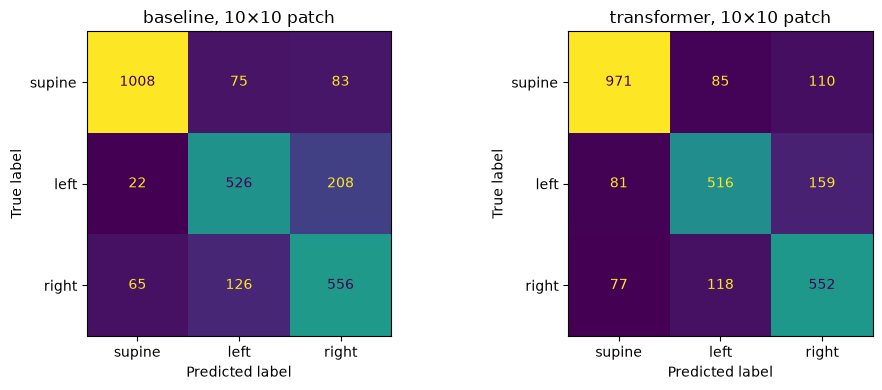

baseline: left and right swapped in 22.2% of side windows
transformer: left and right swapped in 18.4% of side windows


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, patch_pred.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=D.CLASSES).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name}, 10×10 patch")
plt.tight_layout(); plt.show()

for name, pred in patch_pred.items():
    wrong_side = np.isin(y, [1, 2]) & np.isin(pred, [1, 2]) & (y != pred)
    print(f"{name}: left and right swapped in {wrong_side.sum() / np.isin(y, [1, 2]).sum():.1%} of side windows")

This is the most important result so far:

| View | Baseline | Transformer |
|---|---|---|
| Whole bed (Lesson 2) | 95.6 % | 96.5 % |
| **30×30 cm patch** | **76.8 %** | **75.1 %** |

Losing the rest of the body costs about **20 points**. And the mistakes are the ones we care about most: left and right are swapped in about **one side window in five** (22 % baseline, 18 % Transformer).

PmatData people are much harder (63–66 %) than PoPu people (85–89 %). One likely reason is that 60 of the 73 people are from PoPu, so the models learn PoPu's smooth maps better than PmatData's sharper ones. On our own mat we should not assume the better of the two numbers.

## Step 4 · A badly placed mat

A nurse will not place the mat perfectly. `jitter=2` moves the mat up to 2 sensors (about 6 cm) in each direction, differently for every recording. Training on moved mats also teaches the model not to depend on an exact position.

In [9]:
rng = np.random.default_rng(0)
Xj, yj, pj = D.windows_from_recordings(recordings, D.patch_view(positions, jitter=2, rng=rng))
sj = np.array([p.split("-")[0] for p in pj])
jitter_table, _ = evaluate(Xj, yj, pj, sj)
jitter_table

,model,all,PmatData people,PoPu people,macro F1,seconds
0,baseline,0.776,0.683,0.859,0.774,33
1,transformer,0.780,0.685,0.868,0.776,137


A surprise: the score did not fall. It rose a little (baseline 77.6 %, Transformer 78.0 %), even though these test windows are placed badly too. Random placement works like **data augmentation**: each recording sees a slightly different cut, so the model cannot memorise exact cells. So we keep `jitter=2` from now on. The two models are level again.

## Step 5 · Can the small mat look empty with someone in bed?

Lesson 2's empty rule worked on the whole bed. On a 30×30 cm mat there is a new risk: the person may lie beside the mat, so it reads nothing. A rule would then say "empty" while someone is in the bed.

Lesson 2 showed that total pressure separates empty from occupied, while a single hot cell does not. So we cut the same patch from the empty-bed frames, take the largest total as the line, and count how many frames with a person stay under it.

In [10]:
def patch_totals(frames, person):
    return view({"person": person, "frames": frames}).sum(axis=(1, 2))

empty_totals = np.concatenate([patch_totals(D.load_popu_file(D.popu_dir() / str(p) / "empty1.json")[0], f"popu-{p}")
                               for p in range(1, 61)])
line = empty_totals.max()
print(f"total on the patch, empty bed: median {np.median(empty_totals):.0f}, largest {line:.0f}")

supine_level = {}
for r in recordings:
    if r["dataset"] == "popu" and r["label"] == "supine":
        supine_level.setdefault(r["person"], []).append(patch_totals(r["frames"], r["person"]).mean())
supine_level = {person: np.mean(v) for person, v in supine_level.items()}

rows = []
for r in recordings:
    if r["dataset"] == "popu":
        totals = patch_totals(r["frames"], r["person"]) / supine_level[r["person"]]
        rows.append({"label": r["label"], "frames": len(totals), "under_5_percent": int((totals < 0.05).sum()),
                     "under_10_percent": int((totals < 0.10).sum())})
low = pd.DataFrame(rows).groupby("label").sum(numeric_only=True)
for column in ("under_5_percent", "under_10_percent"):
    low[column] = (low[column] / low.frames).round(3)
print("share of frames where the mat reads less than 5 % or 10 % of that person's supine level:")
low

total on the patch, empty bed: median 0, largest 0


share of frames where the mat reads less than 5 % or 10 % of that person's supine level:


,frames,under_5_percent,under_10_percent
label,,,
left,12600,0.0,0.001
right,12600,0.0,0.001
supine,12600,0.0,0.000


Good news, with one caution. On PoPu the patch reads exactly 0 on an empty bed, and with a person in bed it is almost never low: under 10 % of the person's supine level in only 0.1 % of side frames. So here the small mat rarely looks empty.

The caution: a real Velostat mat will not read a clean 0. This check says the idea works, not what the threshold is. It must be measured on our mat.

## What we learned

| Step | Result |
|---|---|
| Sensor spacing, measured from height | about 2.85 cm, so a 10×10 sensor block ≈ our mat |
| Share of body pressure on the mat | 16–30 % |
| Whole bed → patch | about 96 % → about 76 % |
| With placement error, trained for it | 77.6 % baseline, 78.0 % Transformer |
| Left and right swapped on the patch | about 1 in 5 side windows |

- **This is the most honest public-data estimate so far: about 78 %, not 96 %.** It is still from hospital mats, not ours.
- **Left/right is the weak point.** The dashboard should not trust it without a confidence check, and this affects what we can promise on the poster.
- **The Transformer still does not beat the baseline here.** These recordings are still postures.
- **A bigger or differently placed mat might help a lot.** "Your turn" 1 and 2 test that, and it is a hardware decision worth making with data.

## Your turn

1. Try `size=14` in `crop_patch` (a 40×40 cm mat) and resize to 10×10. How much does a bigger mat help? This could guide the hardware.
2. Move the mat down 5 sensors (`top + 5`). Which is better for telling left from right, the hips or the thighs?
3. Add mirror augmentation to the patch data (flip columns, swap left ↔ right).